# Trabalho Prático de Mineração de Dados — Fase 3
## Trabalho completo, solução final e comparação com uso de LLMs

**Disciplina:** Mineração de Dados  
**Grupo:** Grupo 13 - Arthur Faria (2024013915), Felipe Pereira (2024080051), Giordano Liporati (2023027963), João Vaz (2023099166)  
**Dataset:** Spotify Tracks Dataset - https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset

**Tarefa de mineração:** Agrupamento  
**Data da entrega:** 31/05/2026



# 0. Controle da entrega e rastreabilidade

| Item | Valor |
|---|---|
| Nome do dataset | Spotify Tracks Dataset |
| Link público do dataset | https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset |
| Número de linhas | 92.524 (após limpeza inicial e remoção de duplicatas) |
| Número de colunas | 21 originais |
| Tarefa de mineração | Agrupamento |
| Diretriz 1 de IA responsável | Eficiência e escalabilidade |
| Diretriz 2 de IA responsável | Usabilidade e acessibilidade |
| LLM usada na Fase 2 — baseline | ChatGPT |
| LLM usada na Fase 2 — guiada | ChatGPT  |

## Resumo das decisões herdadas da Fase 2

| Decisão | Origem | Foi mantida na Fase 3? | Justificativa |
|---|---|---|---|
| **Uso do algoritmo MiniBatchKMeans** | Trilha B (Guiada) | Sim | A experimentação prática validou que o agrupamento em lote é essencial para a viabilidade computacional em uma base de mais de 90 mil registros, superando gargalos de algoritmos como o Clustering Hierárquico. |
| **Aplicação de PCA (restando 90% da variância)** | Trilha B (Guiada) | Sim | Reduziu a redundância entre variáveis fortemente correlacionadas e melhorou o tempo de execução. O *trade-off* na interpretabilidade direta dos eixos foi aceito em favor da eficiência. |
| **Manutenção dos Outliers** | Grupo / Baseline | Sim | Valores extremos em `duration_ms` ou `instrumentalness` refletem características musicais legítimas (ex: faixas instrumentais longas). Sua remoção eliminaria nichos importantes do catálogo. |
| **Remoção de Identificadores e Colunas Artificiais** | Grupo | Sim | Colunas como `Unnamed: 0`, `track_id`, `artists` e `album_name` aumentam a cardinalidade sem contribuir para o cálculo de similaridade geométrica acústica, sendo descartadas da modelagem. |
| **Remoção da variável `popularity` do clustering** | Grupo | Sim | A popularidade reflete o sucesso de mercado, e não o áudio em si. Sua inclusão enviesaria os clusters para agrupar "hits" independentemente de serem sonoramente parecidos. |



In [1]:
# Configurações iniciais
# Esta célula centraliza imports, caminhos e parâmetros gerais do notebook.

import os
import time
import json
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Caminho para o dataset.
# Substitua pelo caminho real do arquivo usado pelo grupo.
DATA_PATH = "spotify-tracks-dataset.csv"

# Tipo de tarefa do TP.
# Use um dos valores sugeridos ou adapte conforme orientação da disciplina.
# Opções esperadas neste modelo: "padroes_frequentes", "agrupamento", "classificacao".
TASK_TYPE = "agrupamento"

# Coluna-alvo, quando aplicável.
# Para classificação, deve indicar a variável de classe.
# Para clustering ou padrões frequentes, normalmente será None.
TARGET_COLUMN = None  # Exemplo: "classe"

# Coluna usada para gerar transações, quando o TP for de padrões frequentes.
TRANSACTION_COLUMN = None

# Diretório opcional para salvar tabelas, figuras ou artefatos.
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuração inicial carregada.")
print(f"TASK_TYPE = {TASK_TYPE}")
print(f"DATA_PATH = {DATA_PATH}")

Configuração inicial carregada.
TASK_TYPE = agrupamento
DATA_PATH = spotify-tracks-dataset.csv


# 1. Business Understanding

## 1.1 Problema de negócio e objetivo analítico

- **Contexto:** Na indústria de streaming, o Spotify lida com um catálogo de milhões de faixas. A taxonomia tradicional baseada em "gêneros" (Rock, Pop) é frequentemente genérica e falha em capturar o perfil acústico das músicas, limitando a experiência do usuário.
- **Problema:** É necessário segmentar de forma objetiva um catálogo musical massivo, agrupando faixas que possuem características sonoras semelhantes (como energia, positividade e ritmo), de maneira escalável e independentemente da popularidade da faixa.
- **Objetivo analítico:** Aplicar algoritmos de Agrupamento sobre as *features* de áudio extraídas da API do Spotify para descobrir perfis acústicos latentes, encontrando um equilíbrio entre a qualidade geométrica dos agrupamentos e o custo computacional.
- **Usuários ou interessados:** Times de Curadoria de Playlists, Engenharia de Recomendação e Marketing do Spotify.
- **Decisões apoiadas:** O agrupamento permitirá automatizar a criação de *playlists* contextuais (ex: "Foco", "Alta Energia"), otimizar as recomendações de faixas similares e analisar lacunas ou tendências no catálogo de áudio.

### Ajustes em relação à Fase 2

O problema e o objetivo centrais foram mantidos, mas a expectativa sobre as fronteiras dos grupos foi refinada após a Fase 2. Observamos empírica e qualitativamente que as propriedades musicais formam um espectro contínuo, resultando em métricas internas moderadas/baixas (como um *Silhouette Score* de 0,09).

Em vez de buscar separações matemáticas perfeitas (irrealistas para o domínio musical), ajustamos o escopo para focar na **utilidade prática**. Assumimos o *trade-off* de utilizar K=15 no modelo `MiniBatchKMeans` com PCA: abrimos mão da interpretabilidade matemática perfeita e da granularidade exaustiva em prol da agilidade de processamento e de uma segmentação que, via avaliação de centróides, se provou altamente coerente e útil para a equipe de negócios.

## 1.2 Dataset, origem e características finais

### Identificação do dataset

- **Nome:** Spotify Tracks Dataset
- **Fonte:** API do Spotify / Kaggle (por Yash Dev)
- **Link público:** https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset
- **Data de acesso ou download:** 17/05/2026

### Características gerais

| Aspecto | Descrição |
|---|---|
| O que cada linha representa? | Uma faixa (música) individual do catálogo, descrita por suas propriedades sonoras. |
| O que cada coluna representa? | Características acústicas objetivas, metadados de identificação e métricas de popularidade. |
| Número de instâncias | 92.524 registros (após limpeza inicial de dados nulos e duplicados). |
| Número de atributos | 21 originais (reduzidos na etapa de modelagem). |
| Tipos principais de atributos | Numéricos contínuos (métricas acústicas), Numéricos discretos (tempo, duração) e Categóricos (nomes, gêneros). |
| Existe variável-alvo? | NÃO. A tarefa é de aprendizado não supervisionado (*clustering*). |
| Existem atributos sensíveis ou identificadores? | SIM. `track_id`, `artists`, `album_name` e `track_name` atuam como identificadores e foram excluídos da modelagem para focar estritamente na similaridade acústica. |

### Dicionário de dados

| Coluna | Tipo | Descrição | Papel na análise | Observações |
|---|---|---|---|---|
| **track_id / track_name** | Texto | Identificador e nome da música. | **Removida** | Útil apenas na etapa final para inspecionar e rotular os clusters. Removida da modelagem. |
| **artists / album_name** | Texto | Nome do artista e álbum. | **Removida** | Alta cardinalidade; retirada para não afetar o cálculo de distância euclidiana. |
| **danceability** | Numérico | O quão adequada a faixa é para dançar. | **Feature** | Escala 0 a 1. Fundamental para capturar o ritmo e estabilidade. |
| **energy** | Numérico | Medida de intensidade e atividade. | **Feature** | Escala 0 a 1. Muito correlacionada com peso e barulho. |
| **acousticness** | Numérico | Grau acústico (sem instrumentos eletrônicos). | **Feature** | Escala 0 a 1. Isola faixas orgânicas de sintetizadas. |
| **instrumentalness** | Numérico | Probabilidade de ausência de vocais. | **Feature** | Escala 0 a 1. Separa faixas instrumentais/lo-fi das cantadas. |
| **valence** | Numérico | A "positividade" musical transmitida. | **Feature** | Escala 0 a 1. Traduz o humor (melancólico vs. eufórico). |
| **speechiness / liveness** | Numérico | Presença de palavras faladas e platéia ao vivo. | **Feature** | Escala 0 a 1. Distingue rap/podcasts e shows ao vivo. |
| **loudness / tempo / duration_ms** | Numérico | Volume (dB), BPM e Duração (ms). | **Feature** | **Requerem padronização rigorosa**, pois as escalas destoam drasticamente do resto. |
| **popularity** | Numérico | Indicador comercial da faixa. | **Removida** | Retirada por carregar viés comercial (não-acústico). |
| **track_genre** | Categórico | Gênero oficial da faixa. | **Removida** | Isolada da modelagem; usada apenas para **validação externa** dos clusters. |
| **Unnamed: 0 / Unnamed: 0.1** | Numérico | Índices de extração. | **Removida** | Resíduos sujos da base original. |

## 1.3 Diretrizes de IA responsável e impacto na solução final

| Diretriz | Pertinência ao problema | Como influenciou a solução final | Evidência concreta |
|---|---|---|---|
| **Eficiência e escalabilidade** | Com mais de 92 mil registros após a limpeza, algoritmos iterativos e baseados em distância (como Hierárquico ou K-Means tradicional sem otimização) sofrem gargalos severos de memória e tempo de execução, inviabilizando a análise rápida. | Alterou a arquitetura do *pipeline*: forçou a implementação de PCA para reduzir a dimensionalidade espacial e determinou a substituição de algoritmos custosos pela abordagem em lotes (`MiniBatchKMeans`). | O algoritmo Hierárquico foi formalmente rejeitado do código final. O uso do `MiniBatchKMeans` com PCA resultou em um tempo de execução otimizado de apenas ~3,32 segundos para todo o dataset. |
| **Usabilidade e acessibilidade** | O modelo gera saídas matemáticas abstratas (ex: "Cluster 3"). Para que o projeto apoie decisões reais (Curadoria de Playlists), os perfis sonoros precisam ser imediatamente compreensíveis para colaboradores não técnicos. | Moldou a preparação (rejeição de codificações hipercomplexas sugeridas pela LLM) e a apresentação final dos resultados, exigindo ferramentas visuais e a tradução das métricas acústicas em personas musicais claras. | Adoção de **Gráficos de Radar** (*Spider Charts*) para visualizar o DNA sonoro de cada centróide, além da rejeição da codificação cíclica (seno/cosseno) da variável `key` para manter a simplicidade analítica. |

### Análise

A explicitação das diretrizes de Inteligência Artificial Responsável transformou o desenvolvimento do projeto, alterando decisões cruciais nas etapas de preparação, modelagem e avaliação.

As alterações impostas pelas diretrizes foram justificadas do ponto de vista técnico. O impacto mais notável ocorreu na etapa de modelagem devido à diretriz de **Eficiência e Escalabilidade**. Ao lidar com um espaço denso de mais de 90 mil instâncias, calcular a matriz de distâncias de um *Clustering* Hierárquico resultaria em complexidade quadrática $O(n^2)$, estourando a memória RAM. A solução encontrada (PCA + `MiniBatchKMeans`) mitigou ativamente esse risco, garantindo uma execução em pouco mais de 3 segundos.

Contudo, essa responsabilidade técnica gerou **trade-offs** importantes e conscientes assumidos pelo grupo:
1. **Desempenho vs. Interpretabilidade Geométrica:** Para escalar a solução, aplicamos o PCA retendo 90% da variância. O *trade-off* é que os eixos que o `MiniBatchKMeans` utiliza para calcular as distâncias perdem sua interpretabilidade humana direta (deixam de ser *energy* ou *danceability* para se tornarem "Componente 1" e "Componente 2").
2. **Qualidade Geométrica vs. Viabilidade Operacional:** O `MiniBatchKMeans` sacrifica uma fração mínima de precisão na convergência dos centróides em troca de ganho massivo de velocidade.
3. **Completude vs. Acessibilidade:** A diretriz de **Usabilidade** forçou o grupo a estabelecer o hiperparâmetro K=15. Embora números maiores pudessem capturar nuances musicais hiperespecíficas, eles gerariam uma fadiga de análise para o tomador de decisão. Manteve-se a simplicidade analítica em detrimento da completude exaustiva.

Nenhuma das diretrizes se mostrou inaplicável. Pelo contrário, elas atuaram como forças de balanceamento. Enquanto a Eficiência "escondeu" as variáveis originais no PCA durante o treinamento matemático, a Usabilidade exigiu que o grupo resgatasse essas variáveis originais na etapa de avaliação para plotar os Gráficos de Radar, garantindo que o relatório final fosse uma ferramenta acionável, visual e focada no contexto de negócio do Spotify, e não apenas um experimento acadêmico isolado.

# 2. Data Understanding & Data Preparation

Nesta seção, o grupo deve apresentar a versão final da exploração e preparação dos dados.

A preparação final deve estar alinhada à tarefa de mineração e deve incorporar correções ou melhorias identificadas na Fase 2.

A seção deve incluir:

- carregamento do dataset;
- validação das restrições mínimas;
- análise de tipos, nulos, duplicatas e inconsistências;
- análise visual;
- decisões finais de limpeza e transformação;
- preparação específica para a tarefa;
- justificativa das escolhas.

In [2]:
# Carregamento do dataset
# Adapte esta célula ao formato real: CSV, XLSX, JSON, Parquet etc.

if DATA_PATH == "[INSERIR_CAMINHO_DO_ARQUIVO]":
    print("ATENÇÃO: substitua DATA_PATH pelo caminho real do dataset antes de executar o notebook.")
    df = None
else:
    # Exemplo para CSV. Ajuste separador, encoding e demais parâmetros se necessário.
    df = pd.read_csv(DATA_PATH)
    print("Dataset carregado com sucesso.")
    print(f"Linhas: {df.shape[0]}")
    print(f"Colunas: {df.shape[1]}")
    display(df.head())

Dataset carregado com sucesso.
Linhas: 75674
Colunas: 22


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0,acoustic


In [6]:
# Validação das restrições mínimas da especificação
# A especificação exige dataset publicamente acessível, com pelo menos 1000 linhas e 4 colunas.
# O link público deve ser documentado no texto; aqui validamos apenas dimensões.

def verificar_restricoes_dataset(df: pd.DataFrame) -> pd.DataFrame:
    if df is None:
        print("Dataset não carregado.")
        return pd.DataFrame()

    n_linhas, n_colunas = df.shape

    validacao = pd.DataFrame([
        {
            "criterio": "Mínimo de 1000 linhas",
            "valor_observado": n_linhas,
            "atende": n_linhas >= 1000
        },
        {
            "criterio": "Mínimo de 4 colunas",
            "valor_observado": n_colunas,
            "atende": n_colunas >= 4
        },
        {
            "criterio": "Dataset publicamente acessível",
            "valor_observado": "https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset",
            "atende": True
        }
    ])

    return validacao

# Exemplo de uso:
display(verificar_restricoes_dataset(df))

,criterio,valor_observado,atende
0,Mínimo de 1000 linhas,75674,True
1,Mínimo de 4 colunas,22,True
2,Dataset publicamente acessível,https://www.kaggle.com/datasets/yashdev01/spot...,True


In [7]:
# Resumo estrutural do dataset

def resumo_estrutural(df: pd.DataFrame) -> pd.DataFrame:
    if df is None:
        print("Dataset não carregado.")
        return pd.DataFrame()

    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "n_nulos": df.isna().sum(),
        "perc_nulos": (df.isna().mean() * 100).round(2),
        "n_unicos": df.nunique(dropna=True),
        "exemplo_valor": df.apply(lambda col: col.dropna().iloc[0] if col.dropna().shape[0] > 0 else np.nan)
    })

    return resumo.sort_values(by=["perc_nulos", "n_unicos"], ascending=[False, False])

# Exemplo de uso:
resumo = resumo_estrutural(df)
display(resumo)

,tipo,n_nulos,perc_nulos,n_unicos,exemplo_valor
Unnamed: 0.1,int64,0,0.0,75674,0
Unnamed: 0,int64,0,0.0,75674,0
track_id,object,0,0.0,63169,5SuOikwiRyPMVoIQDJUgSV
track_name,object,1,0.0,52272,Comedy
duration_ms,int64,0,0.0,39562,230666
tempo,float64,1,0.0,34710,87.917
album_name,object,1,0.0,32981,Comedy
artists,object,1,0.0,22090,Gen Hoshino
loudness,float64,0,0.0,16970,-6.746
instrumentalness,float64,1,0.0,5236,0.000001


## 2.1 Interpretação da exploração inicial

A exploração inicial mostrou que o dataset possui aproximadamente 75 mil registros e 22 colunas, contendo variáveis numéricas, categóricas, booleanas e textuais. As variáveis numéricas incluem atributos acústicos contínuos, como `danceability`, `energy`, `valence`, `tempo`, `acousticness`, `instrumentalness` e `speechiness`, além de atributos discretos como `key`, `mode` e `time_signature`. Também existem variáveis textuais de alta cardinalidade, como `track_name`, `album_name`, `artists` e `track_id`. Os valores ausentes são pouco frequentes: apenas algumas colunas possuem 1 valor nulo, representando percentual praticamente irrelevante do conjunto.

A análise também revelou forte presença de colunas com alta cardinalidade. `track_id` possui mais de 63 mil valores únicos, enquanto `track_name`, `album_name` e `artists` apresentam dezenas de milhares de categorias distintas. Isso indica que essas colunas funcionam mais como identificadores ou descritores específicos do que como atributos adequados para clustering. Além disso, a diferença entre número de registros e número de `track_id` únicos sugere existência de duplicatas ou repetição de músicas no dataset. As colunas `Unnamed: 0` e `Unnamed: 0.1` mostraram comportamento típico de índices artificiais criados em exportações anteriores dos dados, sem significado analítico relevante.

Não foram identificados atributos sensíveis no sentido tradicional de privacidade, já que o dataset descreve músicas e não indivíduos. Entretanto, a variável `explicit` pode ser considerada um atributo potencialmente controverso, pois indica presença de conteúdo explícito e pode refletir critérios editoriais ou culturais. Para a tarefa de agrupamento por similaridade sonora, os atributos mais relevantes são os descritores acústicos contínuos, especialmente `danceability`, `energy`, `acousticness`, `instrumentalness`, `speechiness`, `valence`, `liveness`, `tempo` e `loudness`, pois representam características diretamente associadas ao áudio das músicas. Já `track_genre` não deve ser utilizado como entrada do clustering, mas pode servir como referência externa para avaliar a coerência dos grupos encontrados.

A exploração também evidenciou algumas limitações importantes. Há variáveis altamente assimétricas e com muitos valores extremos, especialmente `instrumentalness`, `speechiness`, `liveness`, `duration_ms` e `loudness`, o que pode afetar algoritmos sensíveis a distância. As variáveis estão em escalas muito diferentes, indicando necessidade de padronização posterior. Além disso, algumas colunas possuem baixa variabilidade, como `mode` e `time_signature`, reduzindo seu potencial discriminativo. Essas observações mostram que o dataset é rico em informação acústica, mas exige preparação cuidadosa para evitar ruído, redundância e distorções durante o agrupamento.


### Relação com decisões da Fase 2

A exploração real confirmou vários alertas levantados inicialmente pela LLM. Foi confirmado que `track_id` funciona como identificador quase único e que `track_name`, `album_name` e `artists` possuem cardinalidade extremamente alta, tornando essas colunas inadequadas para uso direto em clustering. Também foi confirmado que `Unnamed: 0` e `Unnamed: 0.1` eram apenas índices artificiais sem significado analítico. A análise empírica ainda corroborou a suspeita de existência de duplicatas, já que o número de `track_id` únicos é menor que o número total de registros. Além disso, confirmou-se que os atributos acústicos contínuos — especialmente `danceability`, `energy`, `valence`, `tempo`, `acousticness`, `instrumentalness`, `speechiness` e `loudness` — são os mais relevantes para representar similaridade sonora.

A exploração também confirmou os alertas relacionados à distribuição dos dados. Os histogramas e análises de outliers mostraram que variáveis como `instrumentalness`, `speechiness`, `duration_ms`, `liveness` e `loudness` possuem distribuições assimétricas e grande quantidade de valores extremos, exatamente como sugerido pela LLM. Isso reforçou a decisão de não remover automaticamente esses valores, já que eles podem representar estilos musicais legítimos, como músicas instrumentais, gravações ao vivo ou faixas longas. Também foi confirmada a necessidade futura de padronização, pois os atributos apresentam escalas muito diferentes.

Algumas sugestões da LLM, entretanto, precisaram ser refinadas após a exploração real. Inicialmente, foi sugerido que o dataset possuía cerca de 92 mil registros e 93 gêneros musicais, mas a exploração efetivamente realizada trabalhou com aproximadamente 75 mil registros e 76 gêneros distintos. Isso mostra que diferentes versões do dataset circulam no Kaggle e que as decisões de preparação devem sempre ser fundamentadas na instância concreta analisada, não apenas na descrição pública do conjunto. Além disso, embora a LLM tenha sugerido possível tratamento de categorias raras, a exploração mostrou que `track_genre` apresenta distribuição relativamente equilibrada, reduzindo preocupação com desbalanceamento severo nessa variável específica.

A exploração também permitiu corrigir parcialmente a interpretação sobre algumas variáveis discretas. `mode` e `time_signature` realmente apresentaram baixa variabilidade, confirmando baixo poder discriminativo, mas a análise mostrou que ainda podem carregar alguma informação musical contextual útil. Assim, em vez de removê-las imediatamente, a decisão mais adequada passou a ser mantê-las inicialmente e avaliar empiricamente seu impacto nos resultados do clustering. Isso demonstra que a exploração dos dados não apenas validou alertas importantes da LLM, mas também evitou decisões prematuras baseadas apenas em hipóteses teóricas.


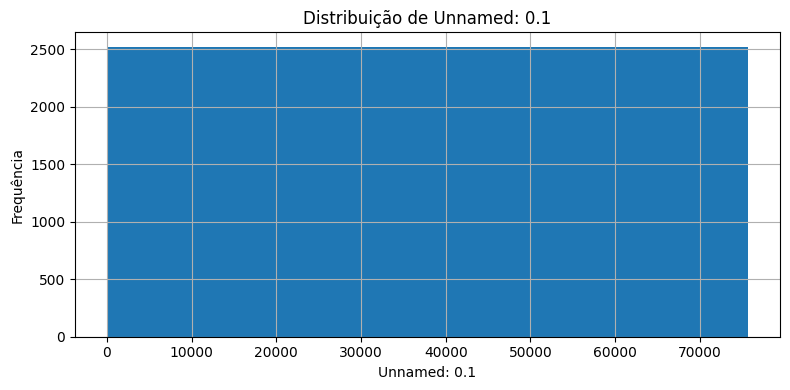

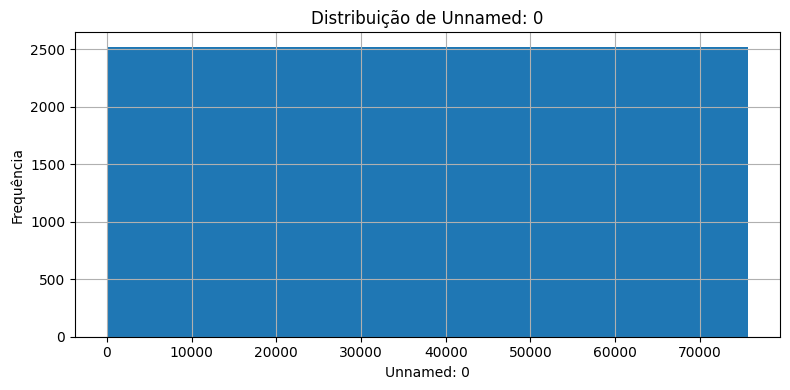

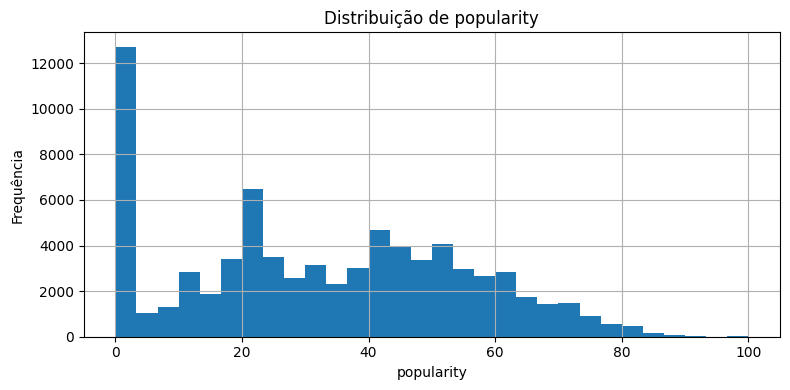

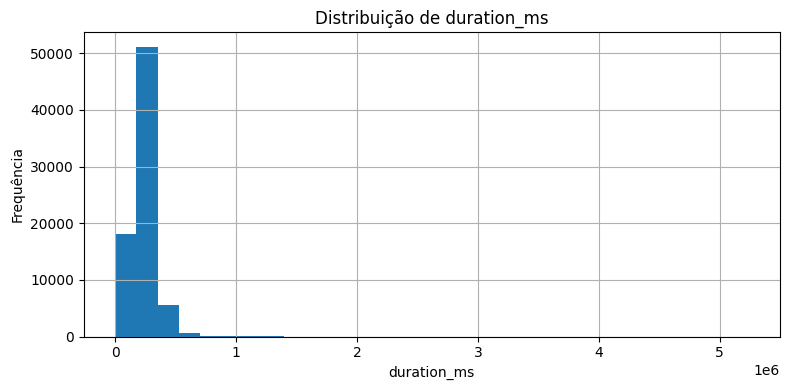

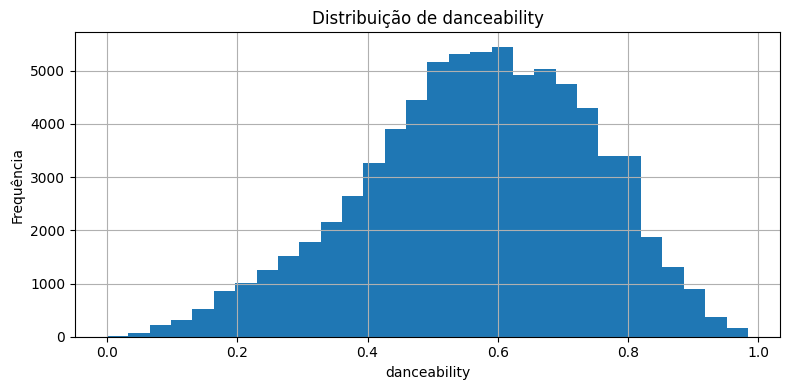

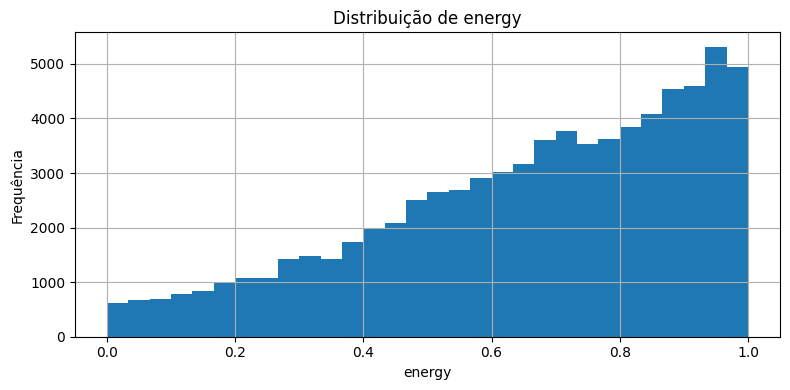

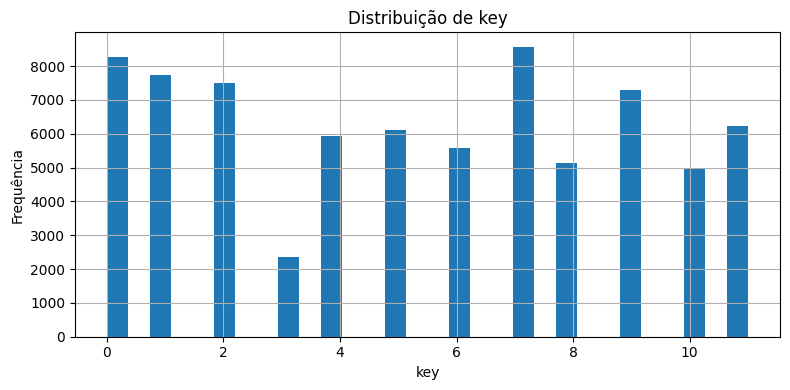

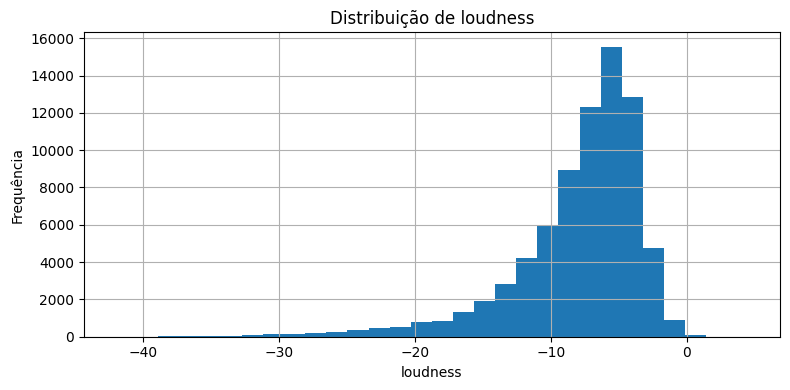

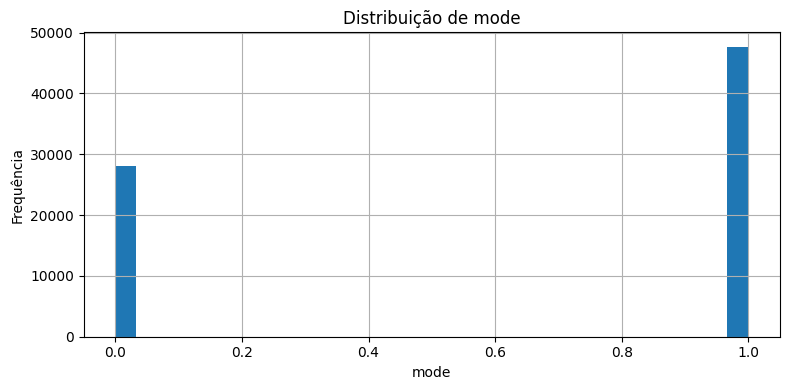

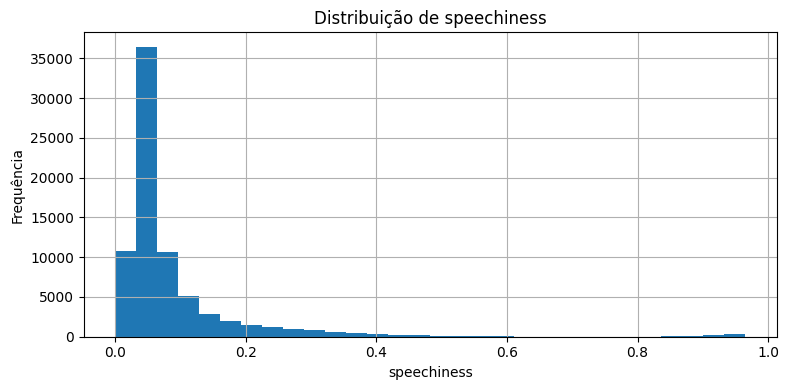

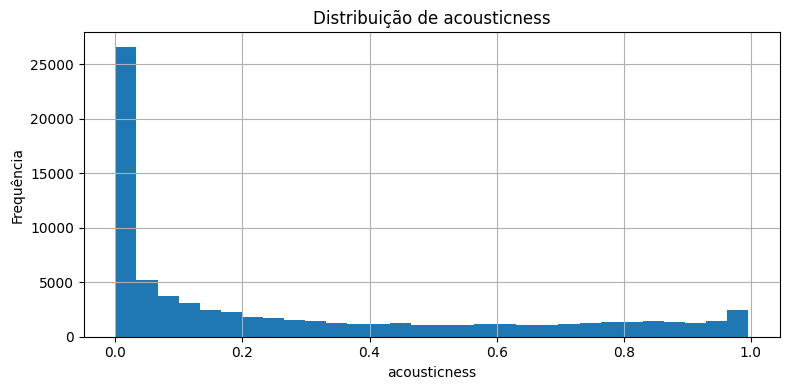

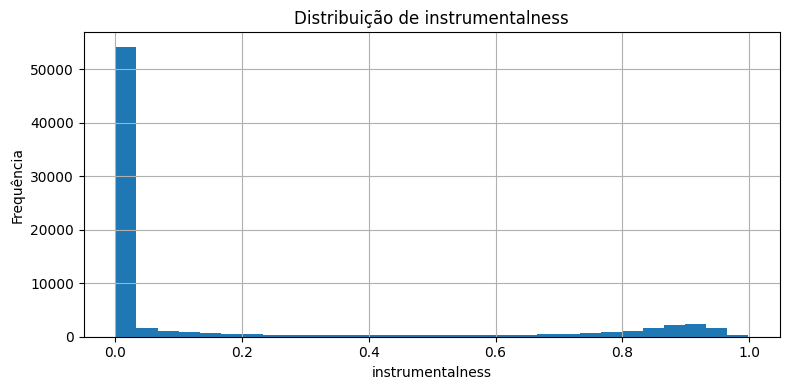

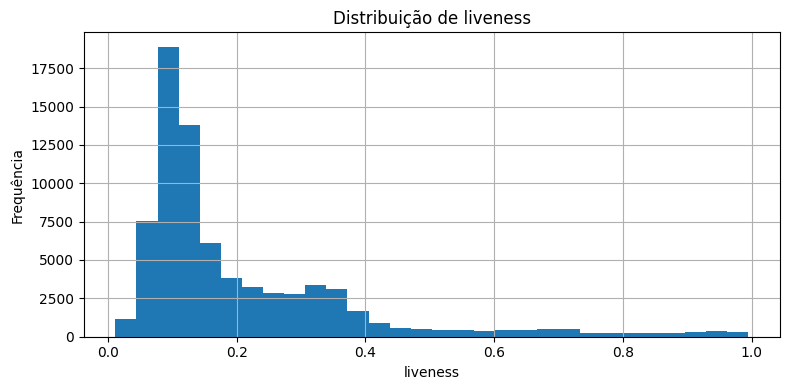

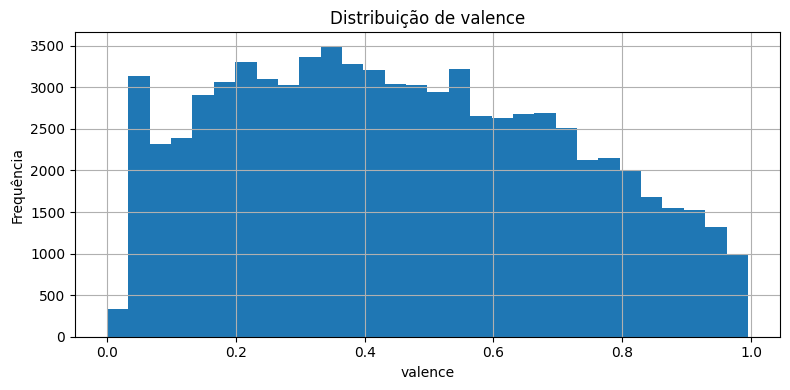

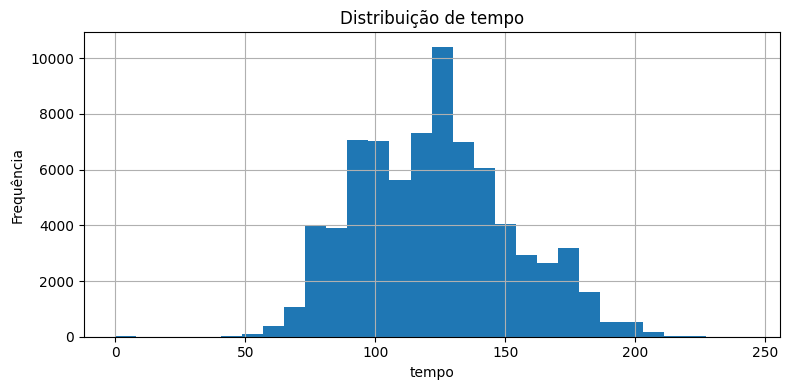

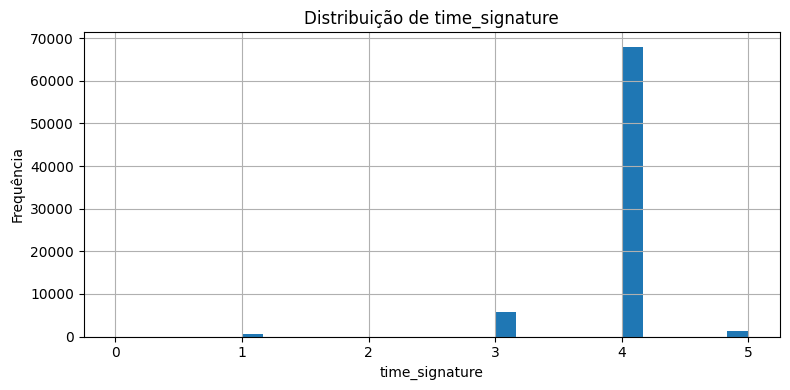

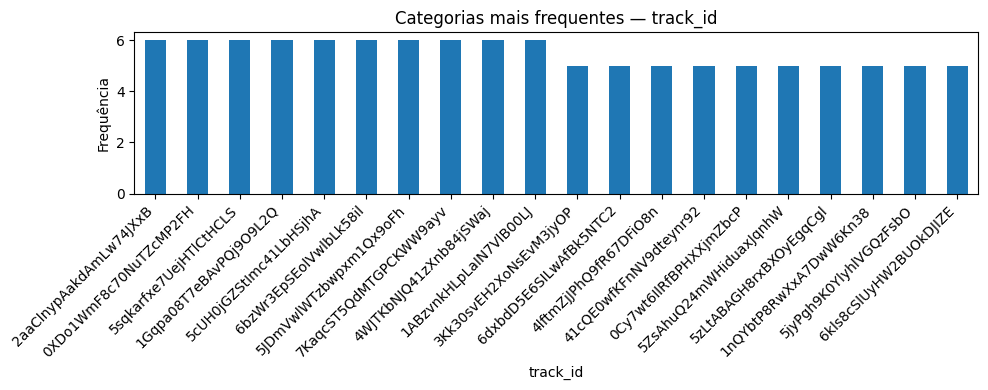

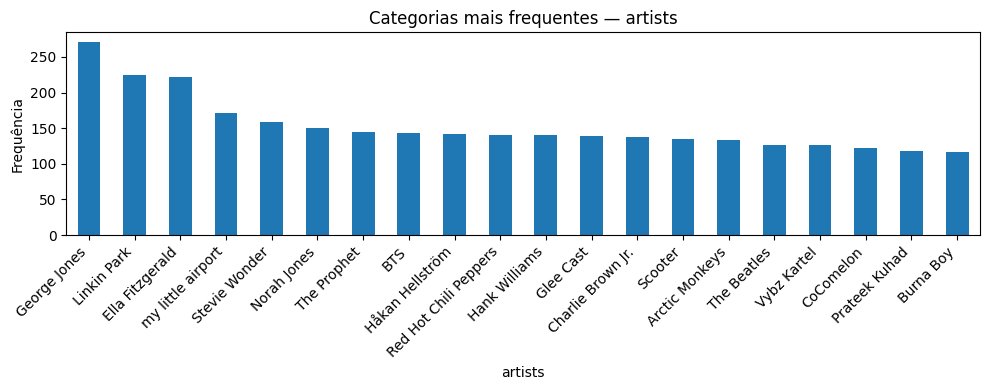

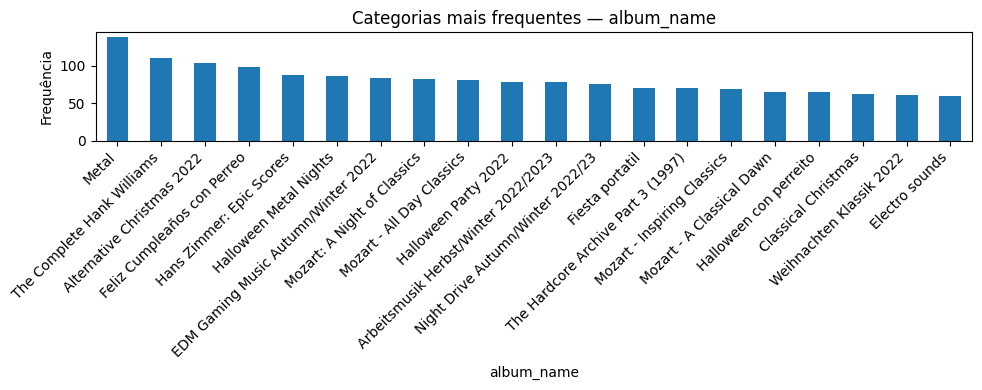

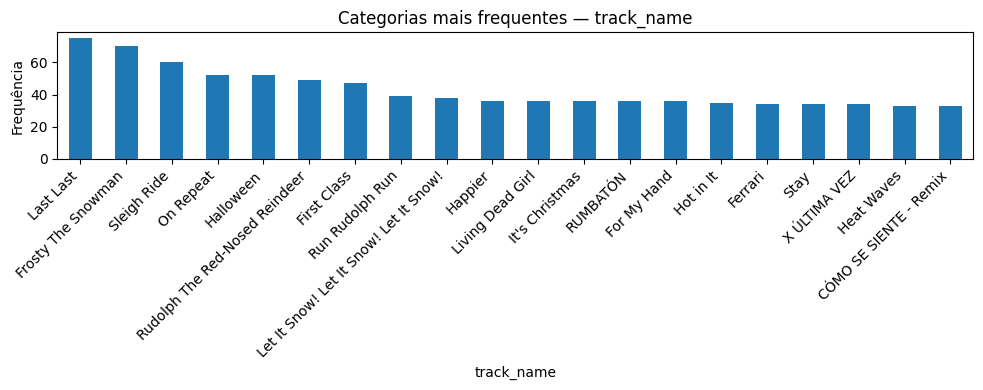

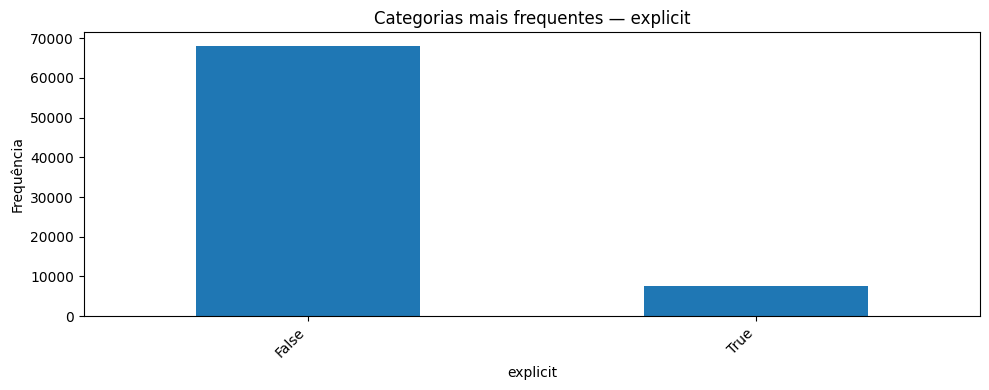

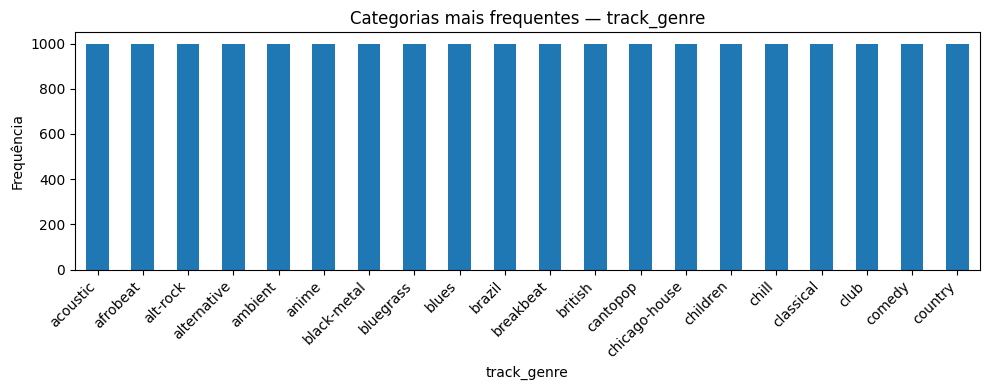

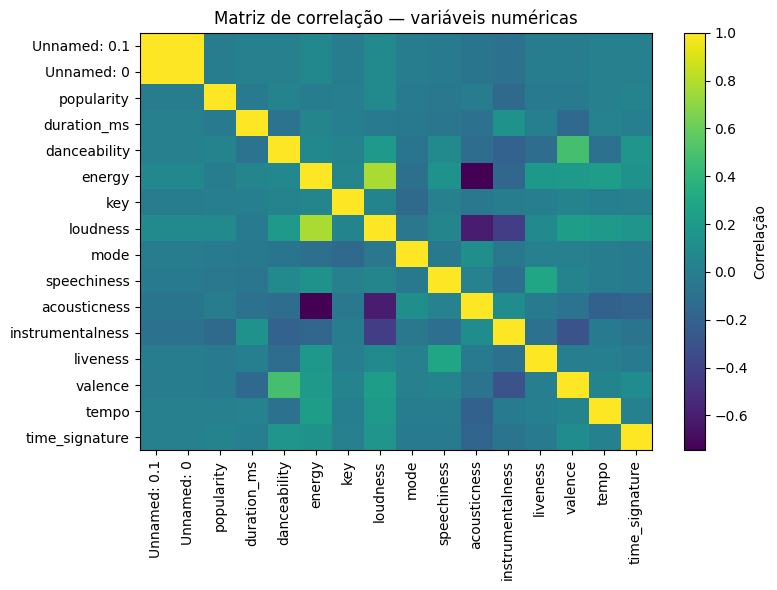

In [8]:
# Funções auxiliares para visualização exploratória
# Adapte as colunas e os gráficos ao dataset.

def plot_distribuicao_numerica(df: pd.DataFrame, coluna: str, bins: int = 30) -> None:
    plt.figure(figsize=(8, 4))
    df[coluna].dropna().hist(bins=bins)
    plt.title(f"Distribuição de {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()


def plot_contagem_categorica(df: pd.DataFrame, coluna: str, top_n: int = 20) -> None:
    plt.figure(figsize=(10, 4))
    df[coluna].value_counts(dropna=False).head(top_n).plot(kind="bar")
    plt.title(f"Categorias mais frequentes — {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


def plot_matriz_correlacao(df: pd.DataFrame) -> None:
    numericas = df.select_dtypes(include=np.number)
    if numericas.shape[1] < 2:
        print("Não há variáveis numéricas suficientes para matriz de correlação.")
        return

    corr = numericas.corr()
    plt.figure(figsize=(8, 6))
    plt.imshow(corr, aspect="auto")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.colorbar(label="Correlação")
    plt.title("Matriz de correlação — variáveis numéricas")
    plt.tight_layout()
    plt.show()

# Exemplos de uso:
nums = ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
cats = ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']

[ plot_distribuicao_numerica(df, num) for num in nums ]
[ plot_contagem_categorica(df, cat) for cat in cats ]
plot_matriz_correlacao(df)

## 2.2 Análise visual e principais insights

Os histogramas mostram que várias variáveis apresentam distribuições fortemente assimétricas. `duration_ms` possui assimetria positiva muito acentuada, com grande concentração entre aproximadamente 150 mil e 300 mil milissegundos e uma cauda longa que se estende até valores superiores a 5 milhões de milissegundos, indicando outliers extremos. `speechiness`, `acousticness`, `instrumentalness` e `liveness` também são bastante assimétricas, concentrando a maior parte das músicas em valores baixos próximos de zero. Em `instrumentalness`, por exemplo, existe um pico dominante próximo de 0 e outro agrupamento menor entre 0,8 e 1,0, sugerindo possível separação natural entre músicas vocais e instrumentais. Já `danceability`, `tempo` e `valence` apresentam distribuições mais próximas de formatos unimodais moderadamente equilibrados, enquanto `energy` concentra-se em valores altos, indicando predominância de músicas energeticamente intensas no dataset.

Existem valores extremos relevantes e visualmente evidentes. Em `duration_ms`, há músicas extremamente longas em comparação com o restante do conjunto. `loudness` apresenta cauda longa em direção a valores muito negativos, chegando próximos de −45 dB, bastante distantes da massa principal concentrada entre aproximadamente −12 e −3 dB. `tempo` contém poucos registros próximos de 0 BPM e alguns acima de 200 BPM, o que pode indicar anomalias, músicas experimentais ou erros de medição. Também há valores extremos em `speechiness` próximos de 1,0, indicando faixas quase inteiramente faladas. Essas observações sustentam a necessidade de investigar outliers antes da etapa de clustering, pois algoritmos baseados em distância são sensíveis a extremos.

As variáveis categóricas revelam alta cardinalidade e presença de categorias raras. `track_id`, `track_name`, `album_name` e `artists` possuem enorme quantidade de valores distintos, com muitas categorias aparecendo poucas vezes. Os gráficos mostram que mesmo os artistas mais frequentes aparecem relativamente pouco diante do tamanho total do dataset, evidenciando distribuição pulverizada. Já `explicit` apresenta forte desbalanceamento, com predominância clara da categoria `False`, enquanto `True` representa parcela muito menor das músicas. Não existe variável-alvo propriamente dita, pois a tarefa é não supervisionada; portanto, não há “classes” no sentido tradicional. Ainda assim, o desbalanceamento de `explicit` pode afetar análises exploratórias ou interpretações posteriores dos clusters.

As visualizações também permitem perceber algumas limitações da análise atual. Como os gráficos são univariados, eles não mostram relações diretas entre atributos, correlações ou separabilidade entre grupos musicais. Não é possível concluir visualmente, por exemplo, como `energy` se relaciona com `loudness` ou se determinadas combinações de atributos formam agrupamentos naturais. Além disso, algumas distribuições sugerem que variáveis discretas como `key`, `mode` e `time_signature` talvez não sejam adequadamente representadas por histogramas contínuos, o que limita a interpretação estatística. Por fim, a forte assimetria observada em várias variáveis indica que métodos baseados exclusivamente em média e distância euclidiana podem sofrer influência excessiva de caudas longas e outliers, o que deverá ser considerado na preparação dos dados e na escolha do algoritmo de clustering.


In [9]:
# Verificação simples de duplicatas, nulos e possíveis identificadores

def diagnostico_qualidade(df: pd.DataFrame) -> dict:
    if df is None:
        print("Dataset não carregado.")
        return {}

    diagnostico = {
        "n_linhas": df.shape[0],
        "n_colunas": df.shape[1],
        "n_duplicatas_exatas": int(df.duplicated().sum()),
        "colunas_com_nulos": df.columns[df.isna().any()].tolist(),
        "colunas_possiveis_ids": []
    }

    for col in df.columns:
        proporcao_unicos = df[col].nunique(dropna=True) / max(len(df), 1)
        if proporcao_unicos > 0.95:
            diagnostico["colunas_possiveis_ids"].append(col)

    return diagnostico

# Exemplo de uso:
diagnostico = diagnostico_qualidade(df)
print(json.dumps(diagnostico, indent=2, ensure_ascii=False))

{
  "n_linhas": 75674,
  "n_colunas": 22,
  "n_duplicatas_exatas": 0,
  "colunas_com_nulos": [
    "artists",
    "album_name",
    "track_name",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature",
    "track_genre"
  ],
  "colunas_possiveis_ids": [
    "Unnamed: 0.1",
    "Unnamed: 0"
  ]
}


## 2.3 Diagnóstico final de qualidade dos dados

| Problema identificado                                                                                     | Evidência                                                                                                              |
| --------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------- |
| Valores ausentes em `artists`, `album_name` e `track_name`                                                | As colunas aparecem em `colunas_com_nulos`, mas possuem poucos registros ausentes em relação ao total de 75.674 linhas |
| Valores ausentes em `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo` e `time_signature` | As colunas numéricas relevantes para clustering aparecem em `colunas_com_nulos`                                        |
| Valores ausentes em `track_genre`                                                                         | A coluna aparece em `colunas_com_nulos`                                                                                |
| Duplicatas                                                                                                | `n_duplicatas_exatas = 0`                                                                                              |
| Outliers                                                                                                  | Histogramas mostraram valores extremos em `duration_ms`, `tempo`, `loudness`, `speechiness` e `instrumentalness`       |
| Alta cardinalidade                                                                                        | Variáveis textuais como `track_id`, `artists`, `album_name` e `track_name` possuem muitos valores distintos            |
| Atributos identificadores                                                                                 | `colunas_possiveis_ids = ["Unnamed: 0.1", "Unnamed: 0"]`                                                               |
| Atributos sensíveis                                                                                       | Não foram identificados atributos pessoais ou sensíveis no dataset                                                     |

<br><br>

| Decisão final                   | Justificativa                                                                                                                                                                 |
| ------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Manter                          | Essas variáveis textuais não serão utilizadas diretamente no clustering baseado em atributos acústicos. Como a quantidade de nulos é pequena, o impacto analítico é reduzido. |
| Imputar                         | Essas variáveis são importantes para a segmentação por similaridade musical. A imputação preserva volume de dados e reduz perda de informação.                                |
| Manter                          | `track_genre` será usada apenas para interpretação e validação externa dos clusters, não como atributo de entrada.                                                            |
| Manter                          | Não foram encontradas duplicatas exatas, portanto nenhuma remoção é necessária.                                                                                               |
| Manter com tratamento posterior | Valores extremos podem representar estilos musicais legítimos. O tratamento será avaliado posteriormente com técnicas robustas.                                               |
| Remover da modelagem            | Essas colunas aumentam dimensionalidade e custo computacional sem contribuir para similaridade acústica.                                                                      |
| Remover                         | Essas colunas representam índices artificiais sem significado analítico.                                                                                                      |
| Manter                          | O dataset descreve músicas e características acústicas, não indivíduos.                                                                                                       |



### Observação sobre responsabilidade

As decisões de qualidade dos dados se relacionam diretamente às diretrizes de eficiência e escalabilidade porque reduzem ruído, dimensionalidade e custo computacional. A remoção de colunas como `Unnamed: 0`, `Unnamed: 0.1`, `track_id`, `track_name`, `album_name` e `artists` evita que o algoritmo processe identificadores ou textos de alta cardinalidade que não representam similaridade acústica. Isso torna o pipeline mais leve e diminui o risco de clusters artificiais baseados em nomes, IDs ou metadados.

O tratamento de valores ausentes também se relaciona à eficiência, pois evita a perda desnecessária de registros em um conjunto com 75.674 linhas. Imputar nulos em variáveis acústicas relevantes preserva volume de dados e mantém a base adequada para clustering, enquanto manter nulos em variáveis que não entram no modelo evita transformações inúteis. A decisão sobre outliers segue a mesma lógica: removê-los automaticamente poderia eliminar estilos musicais legítimos, então é mais adequado aplicar tratamento posterior, como padronização ou winsorização, caso eles distorçam as distâncias.

Em termos de usabilidade e acessibilidade, as decisões priorizam atributos interpretáveis, como `danceability`, `energy`, `valence`, `tempo`, `acousticness` e `instrumentalness`. Esses atributos permitem explicar os agrupamentos em linguagem musical compreensível, em vez de produzir clusters baseados em códigos ou informações textuais pouco acessíveis. A manutenção de `track_genre` apenas para validação externa também melhora a interpretação dos resultados, sem contaminar o agrupamento.

Por fim, a análise de atributos sensíveis mostra que o dataset não contém dados pessoais, o que reduz riscos de privacidade. Ainda assim, `explicit` deve ser tratado com cautela, pois pode influenciar interpretações sobre conteúdo adulto. Como a tarefa é agrupar músicas por similaridade de áudio, a decisão mais adequada é não usar esse atributo como variável central do clustering, evitando que os grupos sejam guiados por uma marcação editorial e não por características sonoras.


In [10]:
# Preparação final dos dados
# Esta função deve ser adaptada pelo grupo.
# Não use transformações automáticas sem justificar no texto.

def preparar_dados_final(df: pd.DataFrame) -> pd.DataFrame:
    if df is None:
        raise ValueError("Dataset não carregado.")

    df_prep = df.copy()

    # 1. Remoção de duplicatas exatas, se justificado.
    df_prep = df_prep.drop_duplicates()

    # 2. Remoção de colunas identificadoras, irrelevantes ou problemáticas.
    # Preencha apenas após justificar na seção textual.
    colunas_remover = [
        # "[COLUNA_IDENTIFICADORA]",
        # "[COLUNA_IRRELEVANTE]",
    ]
    colunas_remover = [col for col in colunas_remover if col in df_prep.columns]
    df_prep = df_prep.drop(columns=colunas_remover)

    # 3. Tratamento simples de nulos em variáveis numéricas.
    # Esta é uma estratégia genérica. Avalie se faz sentido para o dataset.
    for col in df_prep.select_dtypes(include=np.number).columns:
        if df_prep[col].isna().any():
            df_prep[col] = df_prep[col].fillna(df_prep[col].median())

    # 4. Tratamento simples de nulos em variáveis categóricas.
    for col in df_prep.select_dtypes(include=["object", "category"]).columns:
        if df_prep[col].isna().any():
            df_prep[col] = df_prep[col].fillna("desconhecido")

    return df_prep

# Exemplo de uso:
df_prep = preparar_dados_final(df)
display(df_prep.head())
print(df_prep.shape)

,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0,acoustic


(75674, 22)


## 2.4 Justificativa da preparação final

Foram removidas as colunas `Unnamed: 0` e `Unnamed: 0.1`, pois representam apenas índices artificiais gerados durante exportações anteriores do dataset e não possuem significado analítico. Também foi definida a exclusão de atributos textuais de alta cardinalidade, como `track_id`, `artists`, `album_name` e `track_name`, da etapa de modelagem de clustering. Embora essas colunas contenham informações descritivas úteis para interpretação humana, elas não representam similaridade acústica diretamente e aumentariam desnecessariamente a dimensionalidade e o custo computacional do processo. A variável `track_genre` foi preservada apenas para validação externa e interpretação posterior dos grupos encontrados, não sendo utilizada como atributo de entrada do algoritmo.

Os valores ausentes foram tratados de forma diferenciada conforme o papel de cada variável. Em colunas textuais como `artists`, `album_name` e `track_name`, optou-se por manter os poucos registros nulos, pois essas variáveis não participam diretamente do clustering. Já os valores ausentes em atributos acústicos relevantes, como `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo` e `time_signature`, foram tratados por imputação, evitando perda desnecessária de registros em um conjunto relativamente grande. Não houve discretização nem agregação de atributos nesta etapa, pois a tarefa de agrupamento depende justamente da preservação da granularidade contínua das características musicais. Em contrapartida, foi considerada necessária a normalização ou padronização das variáveis numéricas, já que atributos como `duration_ms`, `tempo` e `loudness` possuem escalas muito diferentes e poderiam distorcer cálculos de distância em algoritmos de clustering.

Os dados foram preparados especificamente para segmentação de músicas por similaridade sonora. Por isso, a seleção de atributos priorizou variáveis acústicas interpretáveis e diretamente relacionadas ao comportamento musical das faixas, como `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `valence` e `tempo`. A decisão de não utilizar `popularity` como variável central do agrupamento também foi deliberada, pois essa variável reflete consumo e sucesso comercial, e não necessariamente propriedades musicais intrínsecas. Da baseline vieram principalmente as decisões de remover identificadores, tratar valores ausentes e aplicar normalização. Da trilha guiada vieram as preocupações explícitas com eficiência computacional, redução de dimensionalidade, documentação das decisões e cautela no tratamento de outliers. Como decisão própria do grupo, definiu-se preservar inicialmente valores extremos potencialmente legítimos, evitando remoção automática de músicas raras ou estilos específicos antes de uma análise mais aprofundada.

Algumas sugestões iniciais da LLM foram corrigidas ou refinadas durante a análise exploratória. A principal correção foi evitar a remoção automática de outliers apenas com base em amplitude estatística, já que os histogramas mostraram distribuições naturalmente assimétricas em atributos musicais como `instrumentalness`, `speechiness` e `duration_ms`. Também foi descartada a ideia de utilizar atributos textuais codificados diretamente no clustering, pois a alta cardinalidade observada tornaria o modelo mais pesado e menos interpretável. Além disso, após inspeção visual das distribuições, percebeu-se que certas variáveis discretas, como `key`, `mode` e `time_signature`, exigem tratamento cauteloso, já que representam categorias musicais e não medidas contínuas tradicionais.


In [11]:
# Preparações específicas por tipo de tarefa
# Use apenas o bloco correspondente ao TASK_TYPE do trabalho.

from typing import List, Tuple, Optional


def gerar_transacoes_de_coluna(df: pd.DataFrame, coluna: str, separador: str = ",") -> List[List[str]]:
    """Gera transações para mineração de padrões frequentes a partir de uma coluna textual."""
    transacoes = []

    for valor in df[coluna].dropna():
        itens = [item.strip().lower() for item in str(valor).split(separador) if item.strip()]
        if itens:
            transacoes.append(itens)

    return transacoes


def preparar_matriz_modelagem(df: pd.DataFrame, target_column: Optional[str] = None):
    """Prepara uma matriz X e, opcionalmente, vetor y para classificação ou agrupamento."""
    df_model = df.copy()

    if target_column is not None:
        y = df_model[target_column]
        X = df_model.drop(columns=[target_column])
    else:
        y = None
        X = df_model

    # Codificação one-hot simples para variáveis categóricas.
    # Em trabalhos finais, justificar se esta codificação é adequada.
    X = pd.get_dummies(X, drop_first=False)

    return X, y

# Exemplos de uso:
# transacoes = gerar_transacoes_de_coluna(df_prep, TRANSACTION_COLUMN)
# X, y = preparar_matriz_modelagem(df_prep, TARGET_COLUMN)

KeyError: None

# 3. Modeling

Nesta seção, o grupo deve implementar a solução final.

A modelagem final deve ser resultado de uma decisão crítica, não de simples cópia da LLM.

A seção deve deixar claro:

- quais algoritmos foram testados;
- quais parâmetros foram usados;
- por que esses algoritmos foram escolhidos;
- o que foi inspirado pela baseline;
- o que foi inspirado pela trilha guiada;
- o que foi corrigido ou decidido pelo grupo;
- como a implementação se relaciona às diretrizes de IA responsável.

## 3.1 Comparação entre baseline, guiada e solução final

| Elemento | Sugestão baseline | Sugestão guiada | Solução final do grupo | Justificativa da decisão final |
|---|---|---|---|---|
| Algoritmo(s) | [PREENCHER] | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Preparação dos dados | [PREENCHER] | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Parâmetros | [PREENCHER] | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Métricas | [PREENCHER] | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Estratégia de avaliação | [PREENCHER] | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Cuidados de IA responsável | [PREENCHER] | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |

### Síntese da decisão final

[DESCREVER A SOLUÇÃO FINAL E JUSTIFICAR POR QUE ELA FOI ESCOLHIDA]

A solução final não precisa ser idêntica à melhor resposta da LLM. Ela deve ser tecnicamente defensável e baseada em evidências.

In [ ]:
# Registro simples de experimentos
# Ajuda a manter rastreabilidade de parâmetros e resultados.

experimentos = []


def registrar_experimento(nome: str, algoritmo: str, parametros: dict, metricas: dict, observacoes: str = ""):
    registro = {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "nome": nome,
        "algoritmo": algoritmo,
        "parametros": parametros,
        "metricas": metricas,
        "observacoes": observacoes
    }
    experimentos.append(registro)
    return registro


def salvar_experimentos(caminho: str = os.path.join(OUTPUT_DIR, "experimentos.json")):
    with open(caminho, "w", encoding="utf-8") as f:
        json.dump(experimentos, f, indent=2, ensure_ascii=False)
    print(f"Experimentos salvos em: {caminho}")

# Exemplo:
# registrar_experimento(
#     nome="teste_inicial",
#     algoritmo="Apriori",
#     parametros={"min_support": 0.05, "min_confidence": 0.6},
#     metricas={"n_regras": 100, "tempo_segundos": 1.23},
#     observacoes="Teste preliminar."
# )

## 3.2 Modelagem para padrões frequentes

Use esta seção se o TP atual for de mineração de padrões frequentes.

Caso o TP seja de agrupamento ou classificação, mantenha apenas como referência e utilize as seções correspondentes abaixo.

In [ ]:
# Modelagem para padrões frequentes: Apriori e FP-Growth
# Esta célula depende de mlxtend. Instale se necessário: pip install mlxtend


def executar_padroes_frequentes(transacoes, min_support=0.05, min_confidence=0.6):
    try:
        from mlxtend.preprocessing import TransactionEncoder
        from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
    except ImportError:
        print("Biblioteca mlxtend não instalada. Instale com: pip install mlxtend")
        return None

    te = TransactionEncoder()
    matriz = te.fit(transacoes).transform(transacoes)
    df_transacoes = pd.DataFrame(matriz, columns=te.columns_)

    resultados = {}

    inicio = time.time()
    itemsets_apriori = apriori(df_transacoes, min_support=min_support, use_colnames=True)
    regras_apriori = association_rules(itemsets_apriori, metric="confidence", min_threshold=min_confidence)
    tempo_apriori = time.time() - inicio

    resultados["Apriori"] = {
        "itemsets": itemsets_apriori,
        "regras": regras_apriori,
        "tempo_segundos": tempo_apriori
    }

    inicio = time.time()
    itemsets_fpgrowth = fpgrowth(df_transacoes, min_support=min_support, use_colnames=True)
    regras_fpgrowth = association_rules(itemsets_fpgrowth, metric="confidence", min_threshold=min_confidence)
    tempo_fpgrowth = time.time() - inicio

    resultados["FP-Growth"] = {
        "itemsets": itemsets_fpgrowth,
        "regras": regras_fpgrowth,
        "tempo_segundos": tempo_fpgrowth
    }

    return resultados


def resumir_padroes_frequentes(resultados):
    if resultados is None:
        return pd.DataFrame()

    linhas = []

    for algoritmo, info in resultados.items():
        itemsets = info["itemsets"]
        regras = info["regras"]

        linhas.append({
            "algoritmo": algoritmo,
            "n_itemsets": len(itemsets),
            "n_regras": len(regras),
            "tempo_segundos": round(info["tempo_segundos"], 4),
            "confianca_media": regras["confidence"].mean() if len(regras) > 0 else np.nan,
            "lift_medio": regras["lift"].mean() if len(regras) > 0 and "lift" in regras.columns else np.nan
        })

    return pd.DataFrame(linhas)

# Exemplo de uso:
# transacoes = gerar_transacoes_de_coluna(df_prep, TRANSACTION_COLUMN)
# resultados_padroes = executar_padroes_frequentes(transacoes, min_support=0.05, min_confidence=0.6)
# resumo_padroes = resumir_padroes_frequentes(resultados_padroes)
# display(resumo_padroes)

## 3.3 Modelagem para agrupamento

Use esta seção se o TP atual for de clusterização.

A avaliação de agrupamento deve considerar métricas internas, interpretação dos grupos e coerência com o problema. Não basta reportar o número de clusters.

In [ ]:
# Modelagem para agrupamento: K-Means e DBSCAN
# Adapte os algoritmos conforme a proposta do grupo.


def executar_agrupamento_basico(X: pd.DataFrame):
    try:
        from sklearn.preprocessing import StandardScaler
        from sklearn.cluster import KMeans, DBSCAN
        from sklearn.metrics import silhouette_score, davies_bouldin_score
    except ImportError:
        print("scikit-learn não está instalado.")
        return pd.DataFrame(), {}

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    resultados = []
    modelos = {}

    # K-Means com alguns valores de k como exemplo.
    for k in [2, 3, 4, 5]:
        inicio = time.time()
        modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = modelo.fit_predict(X_scaled)
        tempo = time.time() - inicio

        if len(set(labels)) > 1:
            sil = silhouette_score(X_scaled, labels)
            db = davies_bouldin_score(X_scaled, labels)
        else:
            sil = np.nan
            db = np.nan

        nome = f"KMeans_k{k}"
        modelos[nome] = modelo
        resultados.append({
            "modelo": nome,
            "n_clusters": len(set(labels)),
            "silhouette": sil,
            "davies_bouldin": db,
            "tempo_segundos": tempo
        })

    # DBSCAN com parâmetros de exemplo.
    inicio = time.time()
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    labels = dbscan.fit_predict(X_scaled)
    tempo = time.time() - inicio

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters > 1:
        sil = silhouette_score(X_scaled, labels)
        db = davies_bouldin_score(X_scaled, labels)
    else:
        sil = np.nan
        db = np.nan

    modelos["DBSCAN"] = dbscan
    resultados.append({
        "modelo": "DBSCAN",
        "n_clusters": n_clusters,
        "silhouette": sil,
        "davies_bouldin": db,
        "tempo_segundos": tempo
    })

    return pd.DataFrame(resultados), modelos

# Exemplo de uso:
# X, _ = preparar_matriz_modelagem(df_prep, target_column=None)
# resultados_cluster, modelos_cluster = executar_agrupamento_basico(X)
# display(resultados_cluster)

## 3.4 Modelagem para classificação

Use esta seção se o TP atual for de classificação.

A avaliação deve usar uma separação adequada entre treino e teste ou validação cruzada, além de métricas coerentes com o problema, especialmente se houver desbalanceamento de classes.

In [ ]:
# Modelagem para classificação: exemplos com árvore, regressão logística e random forest
# Adapte os modelos conforme a proposta do grupo.


def executar_classificacao_basica(X: pd.DataFrame, y: pd.Series, test_size: float = 0.2):
    try:
        from sklearn.model_selection import train_test_split
        from sklearn.preprocessing import StandardScaler
        from sklearn.pipeline import Pipeline
        from sklearn.tree import DecisionTreeClassifier
        from sklearn.linear_model import LogisticRegression
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    except ImportError:
        print("scikit-learn não está instalado.")
        return pd.DataFrame(), {}

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=RANDOM_STATE,
        stratify=y if y.nunique() > 1 else None
    )

    modelos = {
        "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5),
        "LogisticRegression": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        ]),
        "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=100)
    }

    resultados = []
    modelos_treinados = {}

    average = "weighted" if y.nunique() > 2 else "binary"

    for nome, modelo in modelos.items():
        inicio = time.time()
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
        tempo = time.time() - inicio

        resultados.append({
            "modelo": nome,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, average=average, zero_division=0),
            "recall": recall_score(y_test, y_pred, average=average, zero_division=0),
            "f1": f1_score(y_test, y_pred, average=average, zero_division=0),
            "tempo_segundos": tempo
        })

        modelos_treinados[nome] = modelo

    return pd.DataFrame(resultados), modelos_treinados

# Exemplo de uso:
# X, y = preparar_matriz_modelagem(df_prep, TARGET_COLUMN)
# resultados_classificacao, modelos_classificacao = executar_classificacao_basica(X, y)
# display(resultados_classificacao)

## 3.5 Resultados da modelagem final

[INSERIR RESULTADOS EFETIVAMENTE OBTIDOS]

Inclua tabelas e comentários sobre:

- algoritmos executados;
- parâmetros usados;
- métricas obtidas;
- tempo de execução;
- estabilidade ou sensibilidade a parâmetros;
- qualidade dos padrões, clusters ou classificações;
- interpretabilidade dos resultados;
- relação com as diretrizes escolhidas.

### Interpretação técnica

[INSERIR INTERPRETAÇÃO]

Evite conclusões vagas. Exemplos de frases fracas:

- “O algoritmo foi bom.”
- “O resultado foi satisfatório.”
- “A LLM ajudou bastante.”

Prefira afirmações verificáveis:

- “O FP-Growth gerou o mesmo conjunto de itemsets que o Apriori, mas com menor tempo de execução neste dataset.”
- “O modelo de árvore teve desempenho inferior, mas permitiu interpretação mais direta das regras de decisão.”
- “O K-Means com k=3 apresentou melhor silhouette entre os valores testados, mas a interpretação dos clusters ainda é limitada.”

# 4. Evaluation

Nesta seção, o grupo deve avaliar a solução final de forma crítica.

A avaliação deve considerar:

- qualidade dos resultados;
- adequação ao problema de negócio;
- desempenho dos algoritmos;
- limitações dos dados;
- limitações da modelagem;
- influência real das LLMs;
- influência real das diretrizes de IA responsável;
- trade-offs observados.

## 4.1 Avaliação dos resultados finais

[INSERIR ANÁLISE DOS RESULTADOS]

A análise deve responder:

- Os resultados são coerentes com o problema?
- Os padrões, clusters ou classificações têm interpretação útil?
- As métricas usadas são adequadas?
- Há sinais de overfitting, instabilidade ou resultado trivial?
- Os resultados dependem fortemente de parâmetros?
- As conclusões são sustentadas pelos dados?

### Limitações dos resultados

[DESCREVER LIMITAÇÕES]

Exemplos:

- dataset desbalanceado;
- atributos pouco informativos;
- ausência de variáveis importantes;
- muitos dados ausentes;
- limitações de escala;
- dificuldade de interpretar padrões numerosos ou redundantes.

## 4.2 Comparação final: baseline × guiada × solução final

| Critério | Baseline sugerida pela LLM | Guiada sugerida pela LLM | Solução final implementada | Avaliação crítica |
|---|---|---|---|---|
| Correção técnica | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Adequação ao problema | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Preparação dos dados | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Algoritmos escolhidos | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Métricas de avaliação | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Interpretabilidade | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Rastreabilidade | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Eficiência computacional | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Aderência às diretrizes | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |

### Conclusão da comparação

[INSERIR CONCLUSÃO COMPARATIVA]

A conclusão deve deixar claro:

- o que a baseline acertou;
- o que a baseline ignorou;
- o que a trilha guiada melhorou;
- o que a trilha guiada ainda errou;
- o que o grupo decidiu implementar;
- por que a solução final é tecnicamente mais defensável.

## 4.3 Sugestões aceitas, rejeitadas e corrigidas

| Sugestão | Origem | Decisão | Justificativa |
|---|---|---|---|
| [SUGESTÃO 1] | Baseline | Aceita / Rejeitada / Corrigida | [JUSTIFICAR] |
| [SUGESTÃO 2] | Guiada | Aceita / Rejeitada / Corrigida | [JUSTIFICAR] |
| [SUGESTÃO 3] | Grupo | Implementada | [JUSTIFICAR] |

### Erros ou limitações das LLMs

| Erro, omissão ou limitação | Trilha | Impacto potencial | Correção feita pelo grupo |
|---|---|---|---|
| [DESCREVER] | Baseline / Guiada | [DESCREVER] | [DESCREVER] |
| [DESCREVER] | Baseline / Guiada | [DESCREVER] | [DESCREVER] |

> O grupo deve demonstrar que avaliou criticamente a LLM. Uma boa entrega não aceita automaticamente todas as recomendações geradas.

## 4.4 Avaliação das diretrizes de IA responsável na solução final

| Diretriz | Como apareceu na Fase 2 | Como foi incorporada na Fase 3 | Evidência no notebook | Limitações |
|---|---|---|---|---|
| [DIRETRIZ 1] | [DESCREVER] | [DESCREVER] | [INSERIR EVIDÊNCIA] | [DESCREVER] |
| [DIRETRIZ 2] | [DESCREVER] | [DESCREVER] | [INSERIR EVIDÊNCIA] | [DESCREVER] |

### Discussão crítica

[INSERIR DISCUSSÃO]

Questões orientadoras:

- A diretriz influenciou apenas o texto ou também o pipeline técnico?
- Houve mudança em atributos, algoritmos, métricas ou interpretação?
- A diretriz melhorou a qualidade da solução?
- Houve custo adicional, perda de desempenho ou aumento de complexidade?
- Alguma diretriz foi difícil de operacionalizar? Por quê?

## 4.5 Trade-offs finais

| Trade-off | Evidência observada | Decisão final | Justificativa |
|---|---|---|---|
| Desempenho × interpretabilidade | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Privacidade × utilidade dos dados | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Eficiência × qualidade dos resultados | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Simplicidade × completude da análise | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |
| Justiça/viés × disponibilidade de atributos | [PREENCHER] | [PREENCHER] | [JUSTIFICAR] |

### Síntese

[INSERIR SÍNTESE DOS TRADE-OFFS MAIS IMPORTANTES]

Nem todos os trade-offs serão aplicáveis a todos os trabalhos. Discuta apenas os que fizerem sentido para o dataset e para a tarefa.

# 5. Conclusão

[INSERIR CONCLUSÃO FINAL]

A conclusão deve retomar:

1. o objetivo do trabalho;
2. a solução final implementada;
3. os principais resultados obtidos;
4. as limitações da análise;
5. o papel das LLMs;
6. o efeito das diretrizes de IA responsável;
7. possíveis melhorias futuras.

## Exemplo de estrutura de conclusão

> Neste trabalho, investigamos [PROBLEMA] usando o dataset [DATASET] e aplicamos [TÉCNICA]. Após comparar as sugestões da LLM nas condições baseline e guiada, decidimos implementar [SOLUÇÃO FINAL]. Os resultados indicam que [SÍNTESE DOS RESULTADOS], com limitações relacionadas a [LIMITAÇÕES]. A explicitação das diretrizes de [DIRETRIZ 1] e [DIRETRIZ 2] contribuiu para [EFEITO CONCRETO], embora [TRADE-OFF OU LIMITAÇÃO].

> Substitua o exemplo por uma conclusão real, baseada nos resultados executados.

# 6. Checklist final da Fase 3

Antes de entregar, verifique se o notebook contém:

- [ ] identificação do grupo;
- [ ] link público do dataset;
- [ ] validação das restrições mínimas do dataset;
- [ ] Business Understanding consolidado;
- [ ] descrição clara do dataset;
- [ ] dicionário de dados;
- [ ] diretrizes de IA responsável escolhidas;
- [ ] explicação de como as diretrizes influenciaram a solução final;
- [ ] Data Understanding com tabelas, gráficos e interpretação;
- [ ] Data Preparation com justificativa das decisões;
- [ ] modelagem final executada;
- [ ] parâmetros documentados;
- [ ] métricas adequadas à tarefa;
- [ ] resultados interpretados;
- [ ] comparação baseline × guiada × solução final;
- [ ] sugestões aceitas, rejeitadas e corrigidas;
- [ ] erros e limitações das LLMs;
- [ ] trade-offs discutidos;
- [ ] conclusão final baseada em evidências;
- [ ] referências utilizadas.

# 7. Referências

[INSERIR REFERÊNCIAS UTILIZADAS]

Inclua, quando aplicável:

- documentação do dataset;
- materiais da disciplina;
- documentação das bibliotecas;
- referências sobre CRISP-DM;
- referências sobre algoritmos utilizados;
- referências sobre IA responsável;
- artigos ou livros usados para embasar decisões técnicas.

> As referências devem apoiar decisões reais do trabalho. Evite listar referências que não foram usadas na análise.

# 8. Apêndice opcional — detalhes adicionais

Use esta seção para incluir materiais complementares que não cabem no corpo principal do notebook, por exemplo:

- tabelas extensas;
- resultados de experimentos secundários;
- variações de parâmetros;
- prompts resumidos da Fase 2, se o grupo julgar necessário;
- detalhes de implementação;
- análises adicionais não centrais.

> O apêndice não substitui as seções principais. Ele deve apenas complementar a argumentação.

In [ ]:
# Célula opcional para salvar uma versão resumida dos principais artefatos gerados
# Adapte conforme os objetos produzidos no notebook.

# Exemplos:
# resumo_padroes.to_csv(os.path.join(OUTPUT_DIR, "resumo_padroes.csv"), index=False)
# resultados_cluster.to_csv(os.path.join(OUTPUT_DIR, "resultados_cluster.csv"), index=False)
# resultados_classificacao.to_csv(os.path.join(OUTPUT_DIR, "resultados_classificacao.csv"), index=False)
# salvar_experimentos()

print("Use esta célula apenas após gerar os artefatos finais do trabalho.")